✅ Данные загружены! Период полных месяцев: 2024-03-01 — 2026-10-01
Строк в agg_monthly_client_kpis: 32
Строк в agg_monthly_client_segments: 1146
Строк в stats_by_clients: 8008


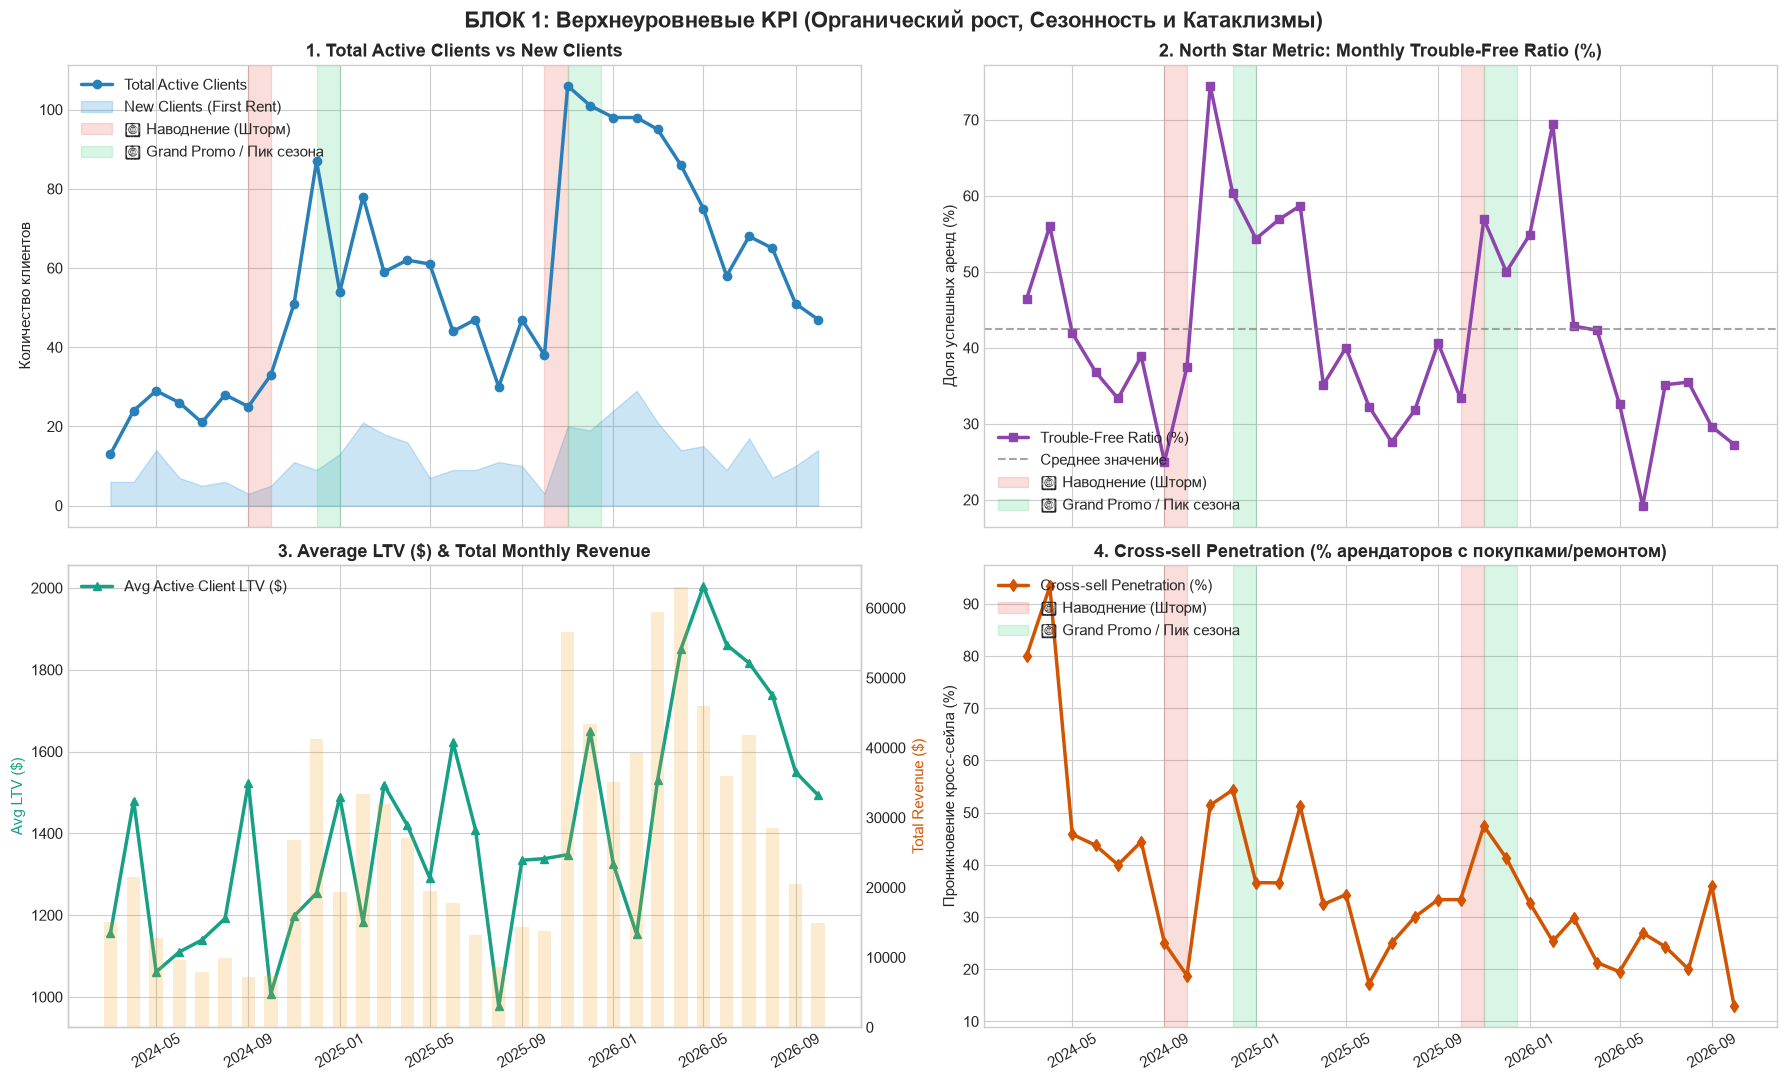

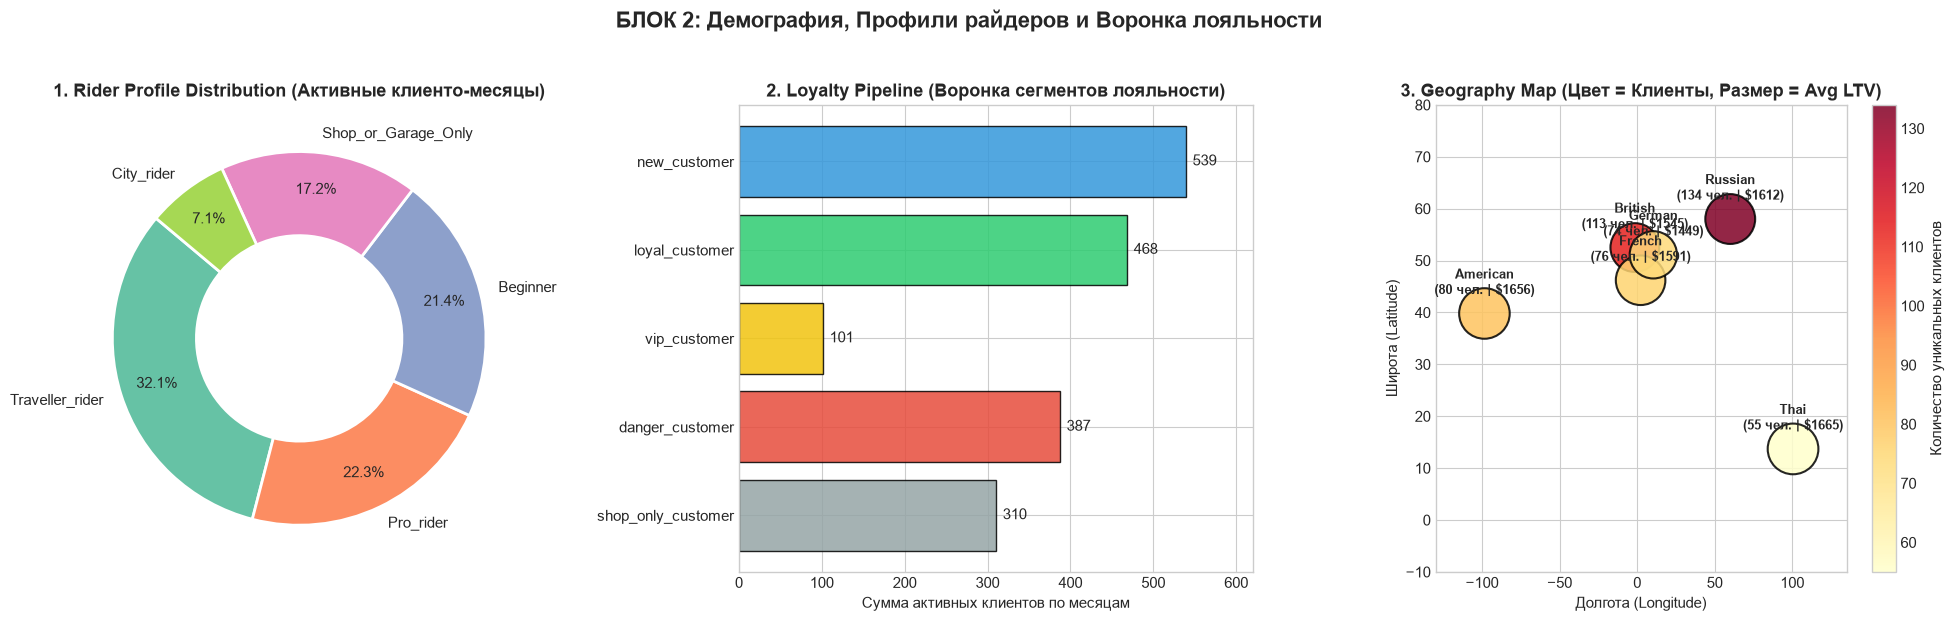

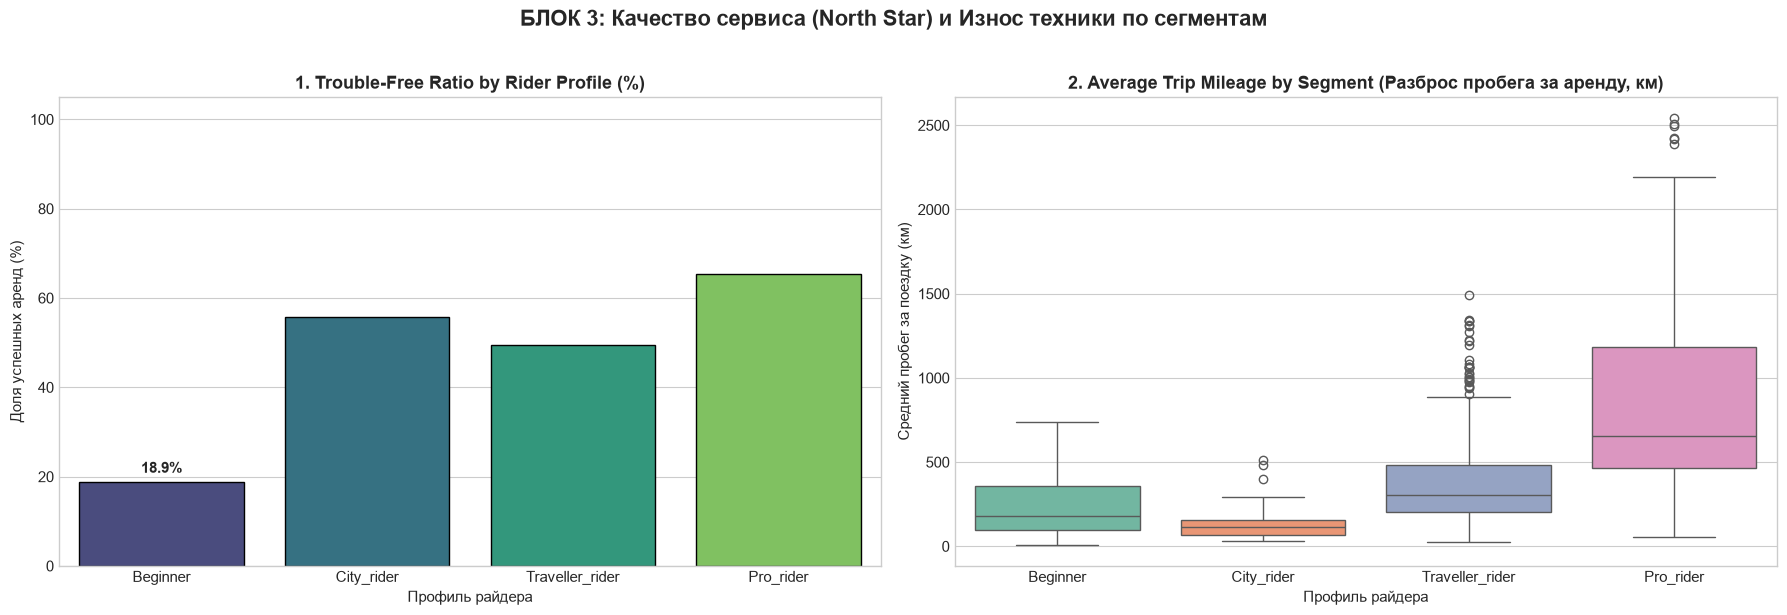

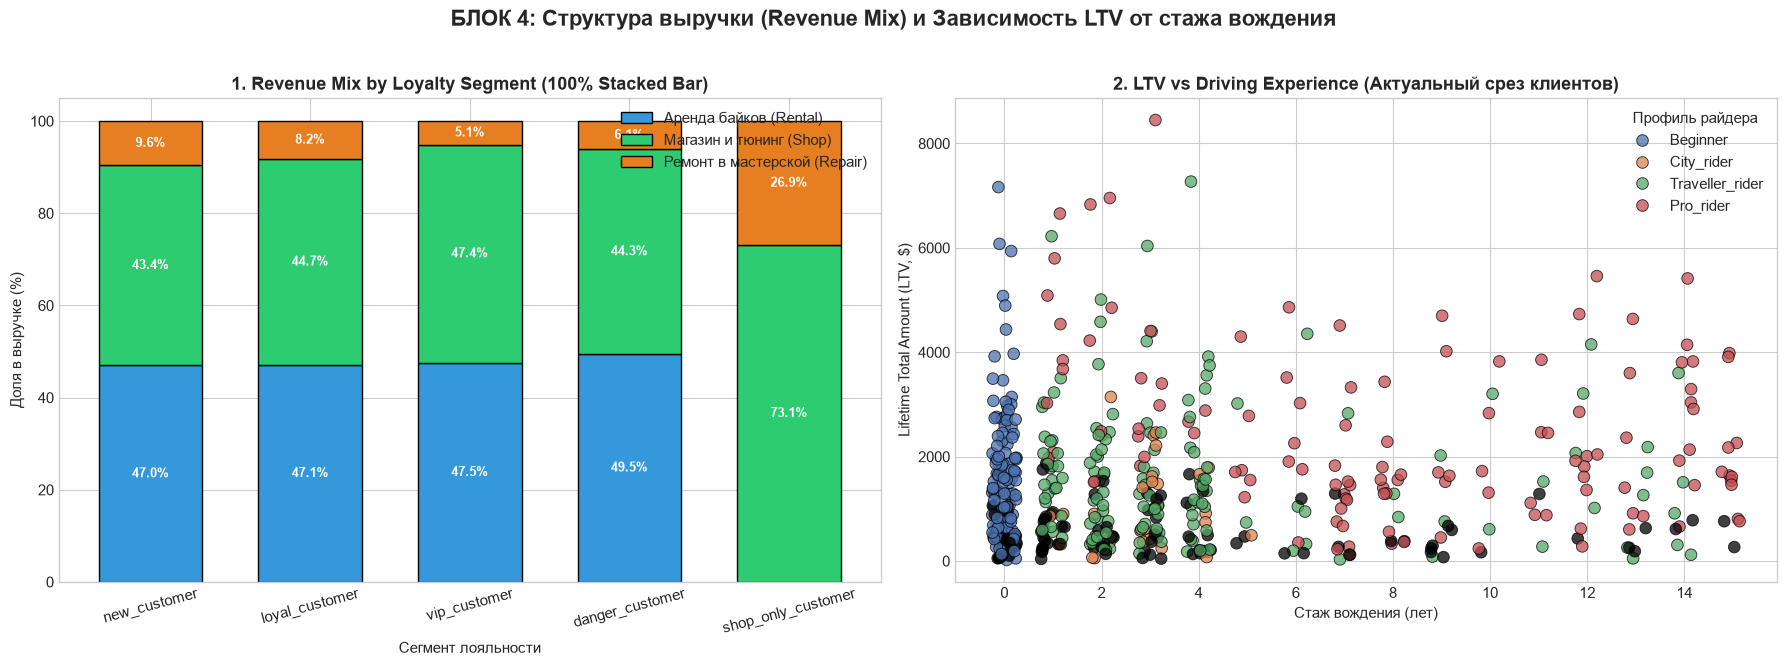

In [1]:
# %% [markdown]
# # 🏍 Top Bikes Bangkok — Валидация данных и Customer Intelligence Dashboard
# Загрузка данных из слоя `aggregations` в PostgreSQL

# %%
import warnings
import psycopg2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (16, 10)
plt.rcParams['font.size'] = 11

# Настройки подключения к локальному DWH
DB_CONFIG = {
    "dbname": "pet_dwh",
    "user": "pet_user",
    "password": "pet_password",
    "host": "localhost",
    "port": "5432"
}

def load_table(table_name):
    """Безопасная загрузка витрины (автопоиск схемы aggregations / public_aggregations)"""
    with psycopg2.connect(**DB_CONFIG) as conn:
        with conn.cursor() as cur:
            cur.execute("""
                SELECT table_schema 
                FROM information_schema.tables 
                WHERE table_name = %s 
                LIMIT 1;
            """, (table_name,))
            row = cur.fetchone()
            if not row:
                raise ValueError(f"Таблица {table_name} не найдена в БД!")
            schema = row[0]
        return pd.read_sql(f"SELECT * FROM {schema}.{table_name}", conn)

df_kpis = load_table("agg_monthly_client_kpis")
df_segments = load_table("agg_monthly_client_segments")
df_sandbox = load_table("stats_by_clients")

# Приводим даты к datetime и сортируем по хронологии
df_kpis['report_month'] = pd.to_datetime(df_kpis['report_month'])
df_segments['report_month'] = pd.to_datetime(df_segments['report_month'])
df_sandbox['report_month'] = pd.to_datetime(df_sandbox['report_month'])

# Исключаем неполный текущий месяц на краю симуляции, чтобы тренды не обрывались вниз
max_complete_month = df_kpis['report_month'].max() - pd.DateOffset(months=1)
df_kpis_clean = df_kpis[df_kpis['report_month'] <= max_complete_month].sort_values('report_month')
df_segments_clean = df_segments[df_segments['report_month'] <= max_complete_month].sort_values('report_month')
df_sandbox_clean = df_sandbox[df_sandbox['report_month'] <= max_complete_month].sort_values('report_month')

print(f"✅ Данные загружены! Период полных месяцев: {df_kpis_clean['report_month'].min().date()} — {df_kpis_clean['report_month'].max().date()}")
print(f"Строк в agg_monthly_client_kpis: {len(df_kpis_clean)}")
print(f"Строк в agg_monthly_client_segments: {len(df_segments_clean)}")
print(f"Строк в stats_by_clients: {len(df_sandbox_clean)}")


# %% [markdown]
# ## Блок 1: Верхнеуровневые KPI (Индикаторы здоровья и проверка сезонности/катаклизмов)

# %%
# Досчитываем помесячный Cross-sell Penetration из песочницы stats_by_clients:
# Доля активных арендаторов месяца, которые также купили товары в магазине или воспользовались ремонтом
renters = df_sandbox_clean[df_sandbox_clean['mtd_rentals'] > 0].copy()
renters['has_cross_sell'] = (renters['mtd_shop_amount'] > 0) | (renters['mtd_repair_amount'] > 0)
cross_sell_monthly = renters.groupby('report_month')['has_cross_sell'].mean().reset_index()
cross_sell_monthly.rename(columns={'has_cross_sell': 'cross_sell_penetration'}, inplace=True)

df_b1 = pd.merge(df_kpis_clean, cross_sell_monthly, on='report_month', how='left')

fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex=True)
fig.suptitle('БЛОК 1: Верхнеуровневые KPI (Органический рост, Сезонность и Катаклизмы)', fontsize=16, fontweight='bold', y=0.98)

# Функция для подсветки катаклизмов и промо-акций на временной шкале
def highlight_events(ax):
    # Наводнения (сентябрь 2024, октябрь 2025)
    ax.axvspan(pd.to_datetime('2024-09-01'), pd.to_datetime('2024-10-01'), color='#e74c3c', alpha=0.18, label='🌊 Наводнение (Шторм)')
    ax.axvspan(pd.to_datetime('2025-10-01'), pd.to_datetime('2025-11-01'), color='#e74c3c', alpha=0.18)
    # Промо и Высокий сезон (ноябрь-декабрь)
    ax.axvspan(pd.to_datetime('2024-12-01'), pd.to_datetime('2025-01-01'), color='#2ecc71', alpha=0.18, label='🎉 Grand Promo / Пик сезона')
    ax.axvspan(pd.to_datetime('2025-11-01'), pd.to_datetime('2025-12-15'), color='#2ecc71', alpha=0.18)

# 1.1 Total Active Clients & New Clients
ax1 = axes[0, 0]
ax1.plot(df_b1['report_month'], df_b1['total_active_clients'], marker='o', linewidth=2.5, color='#2980b9', label='Total Active Clients')
ax1.fill_between(df_b1['report_month'], df_b1['new_clients_count'], color='#3498db', alpha=0.25, label='New Clients (First Rent)')
highlight_events(ax1)
ax1.set_title('1. Total Active Clients vs New Clients', fontweight='bold')
ax1.set_ylabel('Количество клиентов')
ax1.legend(loc='upper left')

# 1.2 North Star Metric (Trouble-Free Ratio)
ax2 = axes[0, 1]
ax2.plot(df_b1['report_month'], df_b1['monthly_trouble_free_ratio'] * 100, marker='s', linewidth=2.5, color='#8e44ad', label='Trouble-Free Ratio (%)')
ax2.axhline(df_b1['monthly_trouble_free_ratio'].mean() * 100, color='gray', linestyle='--', alpha=0.7, label='Среднее значение')
highlight_events(ax2)
ax2.set_title('2. North Star Metric: Monthly Trouble-Free Ratio (%)', fontweight='bold')
ax2.set_ylabel('Доля успешных аренд (%)')
ax2.legend(loc='lower left')

# 1.3 Average Active Client LTV & Total Revenue
ax3 = axes[1, 0]
ax3.plot(df_b1['report_month'], df_b1['avg_active_client_ltv'], marker='^', linewidth=2.5, color='#16a085', label='Avg Active Client LTV ($)')
ax3_twin = ax3.twinx()
ax3_twin.bar(df_b1['report_month'], df_b1['total_monthly_revenue'], width=18, alpha=0.2, color='#f39c12', label='Total Monthly Revenue ($)')
ax3_twin.grid(False)
ax3.set_title('3. Average LTV ($) & Total Monthly Revenue', fontweight='bold')
ax3.set_ylabel('Avg LTV ($)', color='#16a085')
ax3_twin.set_ylabel('Total Revenue ($)', color='#d35400')
ax3.legend(loc='upper left')

# 1.4 Cross-sell Penetration
ax4 = axes[1, 1]
ax4.plot(df_b1['report_month'], df_b1['cross_sell_penetration'] * 100, marker='d', linewidth=2.5, color='#d35400', label='Cross-sell Penetration (%)')
highlight_events(ax4)
ax4.set_title('4. Cross-sell Penetration (% арендаторов с покупками/ремонтом)', fontweight='bold')
ax4.set_ylabel('Проникновение кросс-сейла (%)')
ax4.legend(loc='upper left')

for ax in axes.flat:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


# %% [markdown]
# ## Блок 2: Демография и Сегментация (Кто наши клиенты?)

# %%
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('БЛОК 2: Демография, Профили райдеров и Воронка лояльности', fontsize=16, fontweight='bold', y=1.03)

# 2.1 Rider Profile Distribution (Donut Chart)
ax1 = axes[0]
profile_dist = df_segments_clean.groupby('rider_profile_segment_at_month')['unique_clients_count'].sum().sort_values(ascending=False)
colors_donut = sns.color_palette('Set2', len(profile_dist))
wedges, texts, autotexts = ax1.pie(
    profile_dist.values, 
    labels=profile_dist.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors_donut,
    pctdistance=0.80,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
ax1.set_title('1. Rider Profile Distribution (Активные клиенто-месяцы)', fontweight='bold')

# 2.2 Loyalty Pipeline (Столбчатая воронка лояльности)
ax2 = axes[1]
loyalty_order = ['new_customer', 'loyal_customer', 'vip_customer', 'danger_customer', 'shop_only_customer']
profile_order = ['Beginner', 'City_rider', 'Traveller_rider', 'Pro_rider', 'Shop_or_Garage_Only']
loyalty_dist = df_segments_clean.groupby('loyalty_segment_at_month')['unique_clients_count'].sum().reindex(loyalty_order).dropna()
palette_loyalty = ['#3498db', '#2ecc71', '#f1c40f', '#e74c3c', '#95a5a6']
bars = ax2.barh(loyalty_dist.index[::-1], loyalty_dist.values[::-1], color=palette_loyalty[:len(loyalty_dist)][::-1], edgecolor='black', alpha=0.85)
ax2.bar_label(bars, padding=5, fmt='%d')
ax2.set_title('2. Loyalty Pipeline (Воронка сегментов лояльности)', fontweight='bold')
ax2.set_xlabel('Сумма активных клиентов по месяцам')
ax2.margins(x=0.15)

# 2.3 Geography Map (Карта мира по национальностям: цвет = кол-во клиентов, размер = средний LTV)
ax3 = axes[2]
# Берем последний актуальный срез каждого уникального клиента из песочницы
latest_clients = df_sandbox_clean.sort_values('report_month').groupby('client_natural_key').last().reset_index()
geo_stats = latest_clients.groupby('nationality').agg(
    client_count=('client_natural_key', 'count'),
    avg_ltv=('lifetime_total_amount', 'mean')
).reset_index()

# Координаты центров стран (долгота, широта) для отрисовки на карте мира
coords = {
    'American': (-98.5, 39.8),
    'British': (-1.5, 52.5),
    'French': (2.2, 46.2),
    'German': (10.4, 51.1),
    'Russian': (60.0, 58.0),
    'Thai': (100.5, 13.7)
}
geo_stats['lon'] = geo_stats['nationality'].map(lambda x: coords.get(x, (0, 0))[0])
geo_stats['lat'] = geo_stats['nationality'].map(lambda x: coords.get(x, (0, 0))[1])

scatter = ax3.scatter(
    geo_stats['lon'], 
    geo_stats['lat'], 
    s=geo_stats['avg_ltv'] * 0.8,      # Размер точки = средний LTV
    c=geo_stats['client_count'],       # Интенсивность цвета = количество клиентов
    cmap='YlOrRd', 
    alpha=0.85, 
    edgecolors='black', 
    linewidth=1.5
)
for _, row in geo_stats.iterrows():
    ax3.annotate(
        f"{row['nationality']}\n({row['client_count']} чел. | ${row['avg_ltv']:.0f})",
        (row['lon'], row['lat']),
        textcoords="offset points",
        xytext=(0, 14),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )
plt.colorbar(scatter, ax=ax3, label='Количество уникальных клиентов')
ax3.set_xlim(-130, 135)
ax3.set_ylim(-10, 80)
ax3.set_title('3. Geography Map (Цвет = Клиенты, Размер = Avg LTV)', fontweight='bold')
ax3.set_xlabel('Долгота (Longitude)')
ax3.set_ylabel('Широта (Latitude)')

plt.tight_layout()
plt.show()


# %% [markdown]
# ## Блок 3: Качество сервиса и Безопасность (North Star в разрезах)

# %%
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('БЛОК 3: Качество сервиса (North Star) и Износ техники по сегментам', fontsize=16, fontweight='bold', y=1.02)

# Оставляем только строки, где реально были аренды (segment_trouble_free_ratio IS NOT NULL)
df_seg_rentals = df_segments_clean[df_segments_clean['segment_trouble_free_ratio'].notna()].copy()
profile_order = ['Beginner', 'City_rider', 'Traveller_rider', 'Pro_rider', 'unknown']
existing_profiles = [p for p in profile_order if p in df_seg_rentals['rider_profile_segment_at_month'].unique()]

# 3.1 Trouble-Free Ratio by Rider Profile (Взвешенное среднее по числу клиентов)
ax1 = axes[0]
tfr_by_profile = (
    df_seg_rentals.groupby('rider_profile_segment_at_month')
    .apply(lambda g: np.average(g['segment_trouble_free_ratio'], weights=g['unique_clients_count']) * 100)
    .reindex(existing_profiles)
)
bars1 = sns.barplot(x=tfr_by_profile.index, y=tfr_by_profile.values, ax=ax1, palette='viridis', edgecolor='black')
ax1.bar_label(ax1.containers[0], fmt='%.1f%%', padding=4, fontweight='bold')
ax1.set_ylim(0, 105)
ax1.set_title('1. Trouble-Free Ratio by Rider Profile (%)', fontweight='bold')
ax1.set_xlabel('Профиль райдера')
ax1.set_ylabel('Доля успешных аренд (%)')

# 3.2 Average Trip Mileage by Segment (Box Plot)
ax2 = axes[1]
df_mileage = df_seg_rentals[df_seg_rentals['avg_trip_mileage'] > 0]
sns.boxplot(
    data=df_mileage, 
    x='rider_profile_segment_at_month', 
    y='avg_trip_mileage', 
    order=existing_profiles,
    palette='Set2', 
    ax=ax2,
    showfliers=True
)
ax2.set_title('2. Average Trip Mileage by Segment (Разброс пробега за аренду, км)', fontweight='bold')
ax2.set_xlabel('Профиль райдера')
ax2.set_ylabel('Средний пробег за поездку (км)')

plt.tight_layout()
plt.show()


# %% [markdown]
# ## Блок 4: Монетизация и Кросс-сейл (Где наши деньги?)

# %%
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
fig.suptitle('БЛОК 4: Структура выручки (Revenue Mix) и Зависимость LTV от стажа вождения', fontsize=16, fontweight='bold', y=1.02)

# 4.1 Revenue Mix by Loyalty Segment (100% Stacked Bar Chart)
ax1 = axes[0]
rev_by_loyalty = (
    df_segments_clean.groupby('loyalty_segment_at_month')[['sum_rental_amount', 'sum_shop_amount', 'sum_repair_amount']]
    .sum()
    .reindex([l for l in loyalty_order if l in df_segments_clean['loyalty_segment_at_month'].unique()])
)
rev_pct = rev_by_loyalty.div(rev_by_loyalty.sum(axis=1), axis=0) * 100

rev_pct.plot(
    kind='bar', 
    stacked=True, 
    ax=ax1, 
    color=['#3498db', '#2ecc71', '#e67e22'], 
    edgecolor='black', 
    width=0.65
)
ax1.set_title('1. Revenue Mix by Loyalty Segment (100% Stacked Bar)', fontweight='bold')
ax1.set_xlabel('Сегмент лояльности')
ax1.set_ylabel('Доля в выручке (%)')
ax1.legend(['Аренда байков (Rental)', 'Магазин и тюнинг (Shop)', 'Ремонт в мастерской (Repair)'], loc='upper right')
ax1.tick_params(axis='x', rotation=15)

# Подписываем проценты внутри столбцов
for container in ax1.containers:
    labels = [f'{v.get_height():.1f}%' if v.get_height() >= 5 else '' for v in container]
    ax1.bar_label(container, labels=labels, label_type='center', fontsize=9, fontweight='bold', color='white')

# 4.2 LTV vs Driving Experience (Scatter Plot на актуальном срезе клиентов)
ax2 = axes[1]
# Добавляем легкий джиттер по оси X, чтобы точки с одинаковым целым стажем (0, 1, 2 года) не сливались в одну линию
latest_clients['exp_jitter'] = latest_clients['driving_experience_years'] + np.random.uniform(-0.25, 0.25, size=len(latest_clients))

sns.scatterplot(
    data=latest_clients,
    x='exp_jitter',
    y='lifetime_total_amount',
    hue='rider_profile_segment_at_month',
    hue_order=[p for p in profile_order if p in latest_clients['rider_profile_segment_at_month'].unique()],
    palette='deep',
    alpha=0.75,
    s=70,
    edgecolor='black',
    ax=ax2
)
ax2.set_title('2. LTV vs Driving Experience (Актуальный срез клиентов)', fontweight='bold')
ax2.set_xlabel('Стаж вождения (лет)')
ax2.set_ylabel('Lifetime Total Amount (LTV, $)')
ax2.legend(title='Профиль райдера', loc='upper right')

plt.tight_layout()
plt.show()

✅ Операционные витрины загружены! Полный период: 2024-03-01 — 2026-10-01
Строк в agg_monthly_ops_kpis: 32
Строк в agg_monthly_fleet_utilization: 320
Строк в agg_monthly_supply_and_repairs: 192
Строк в stats_by_bikes: 1760 | stats_by_inventory: 15552


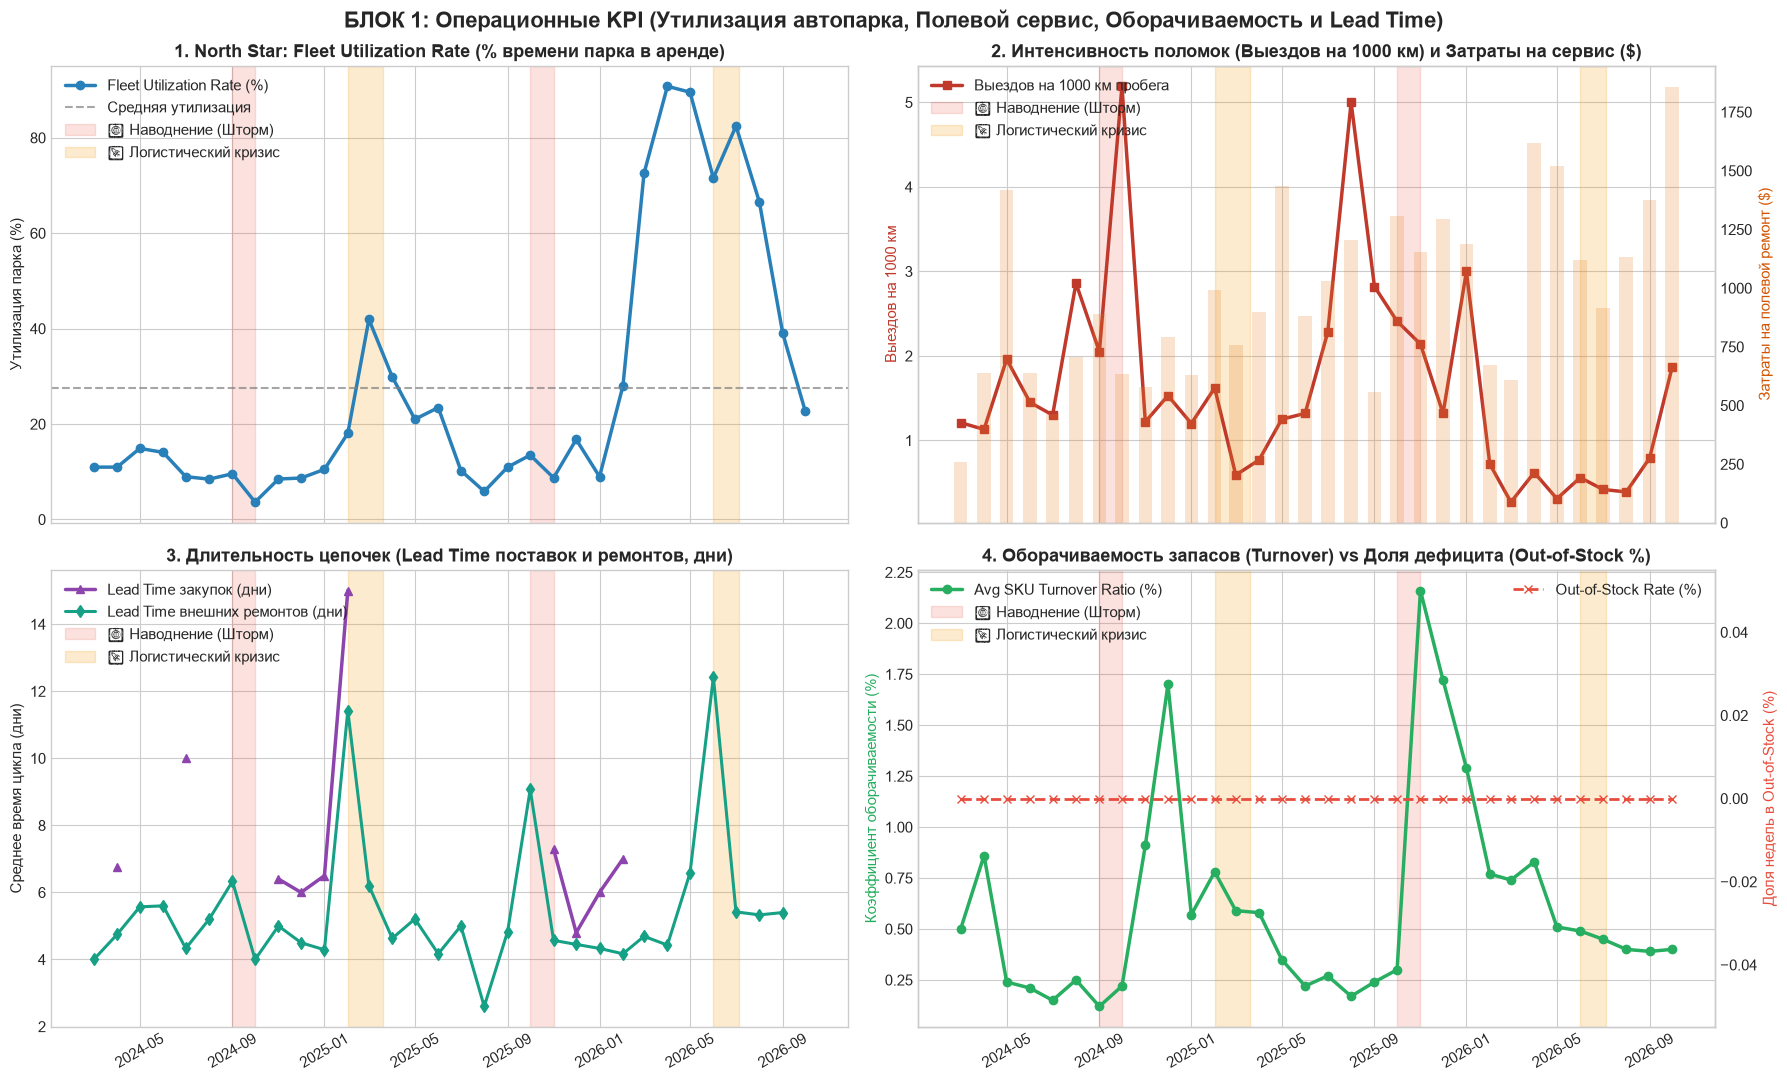

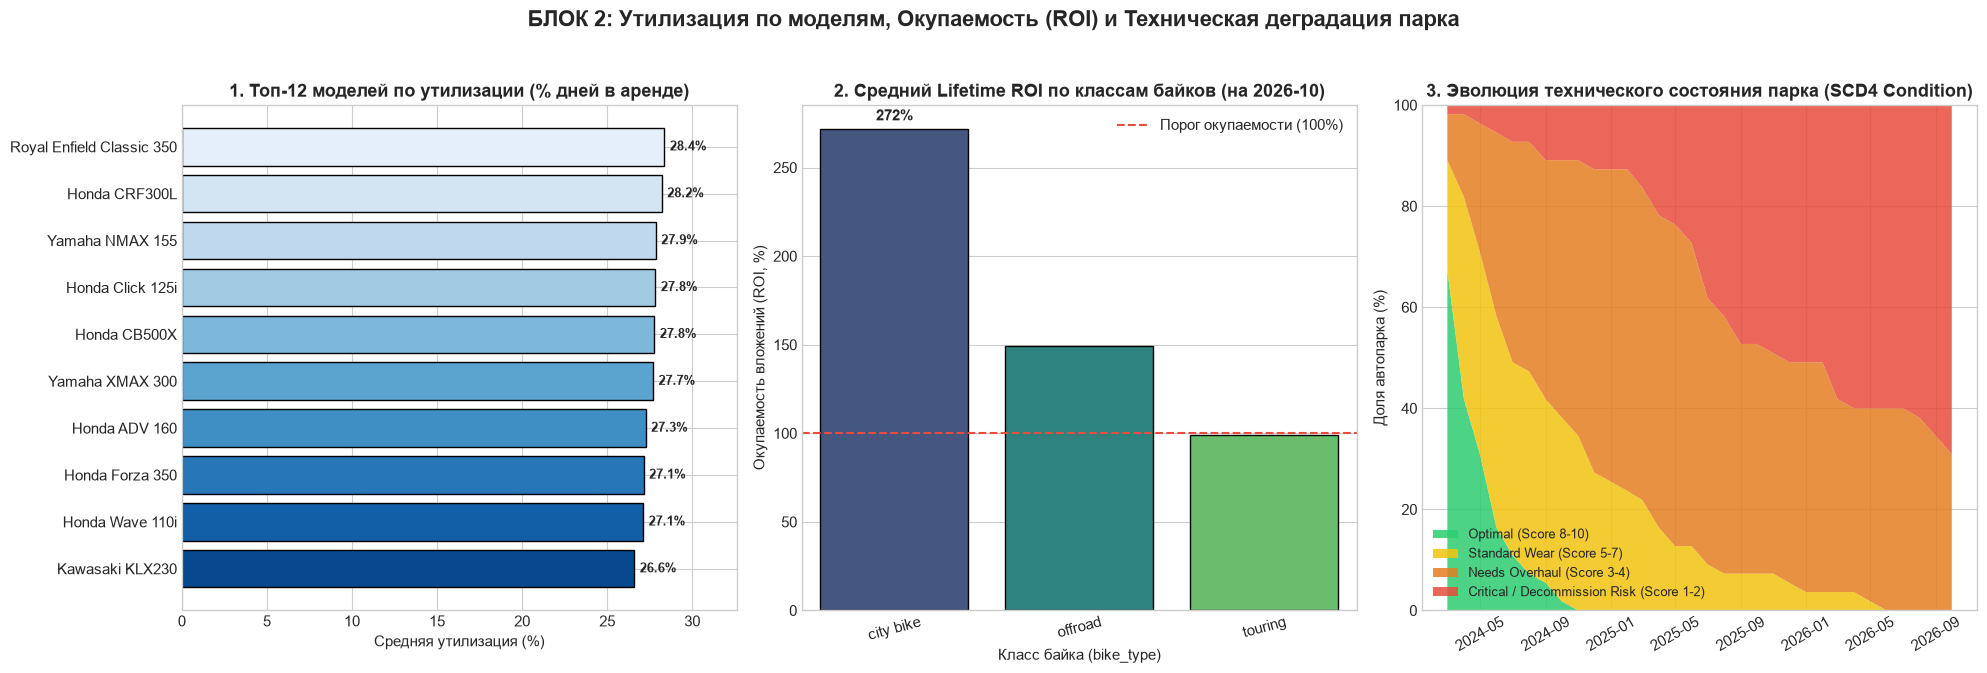

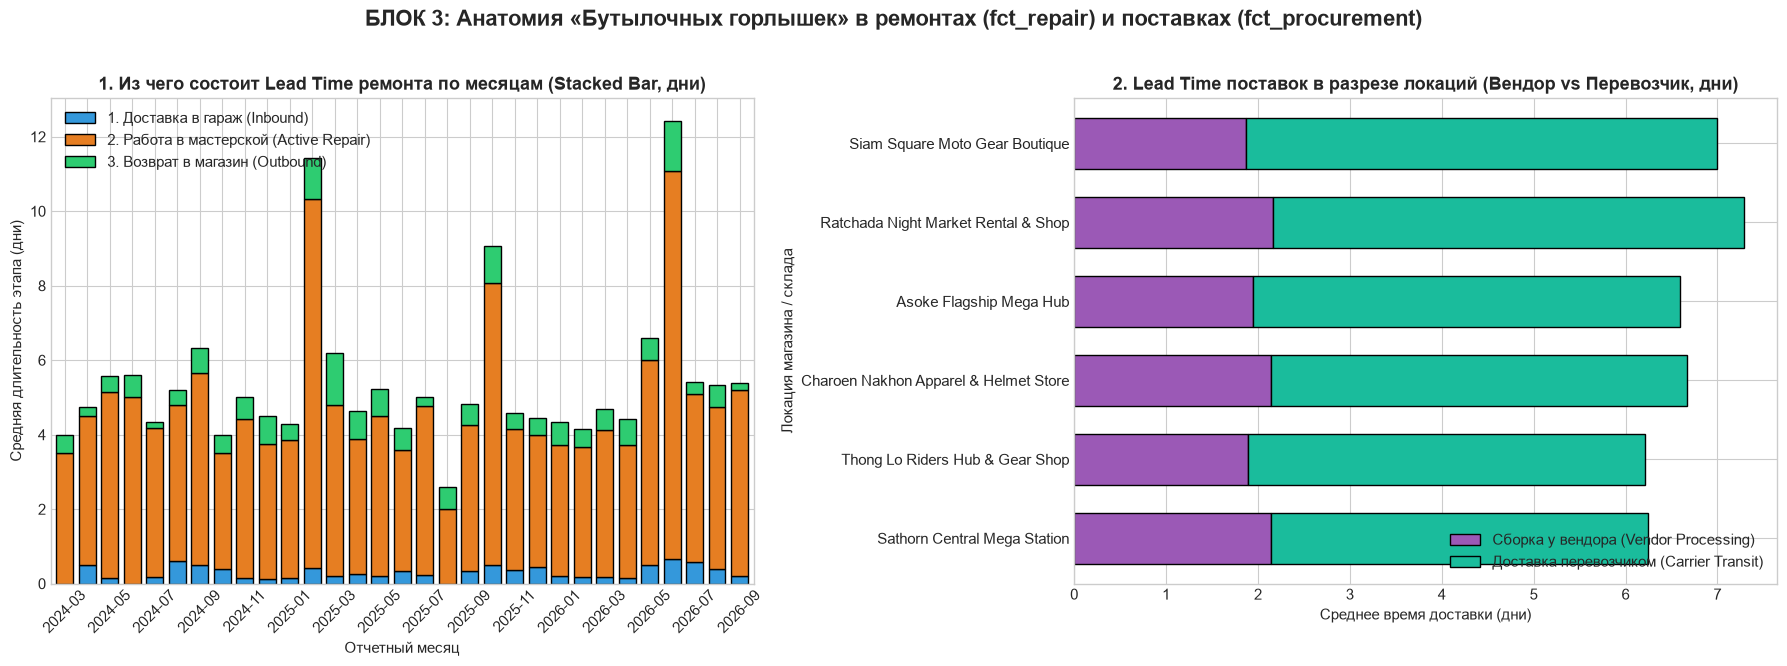

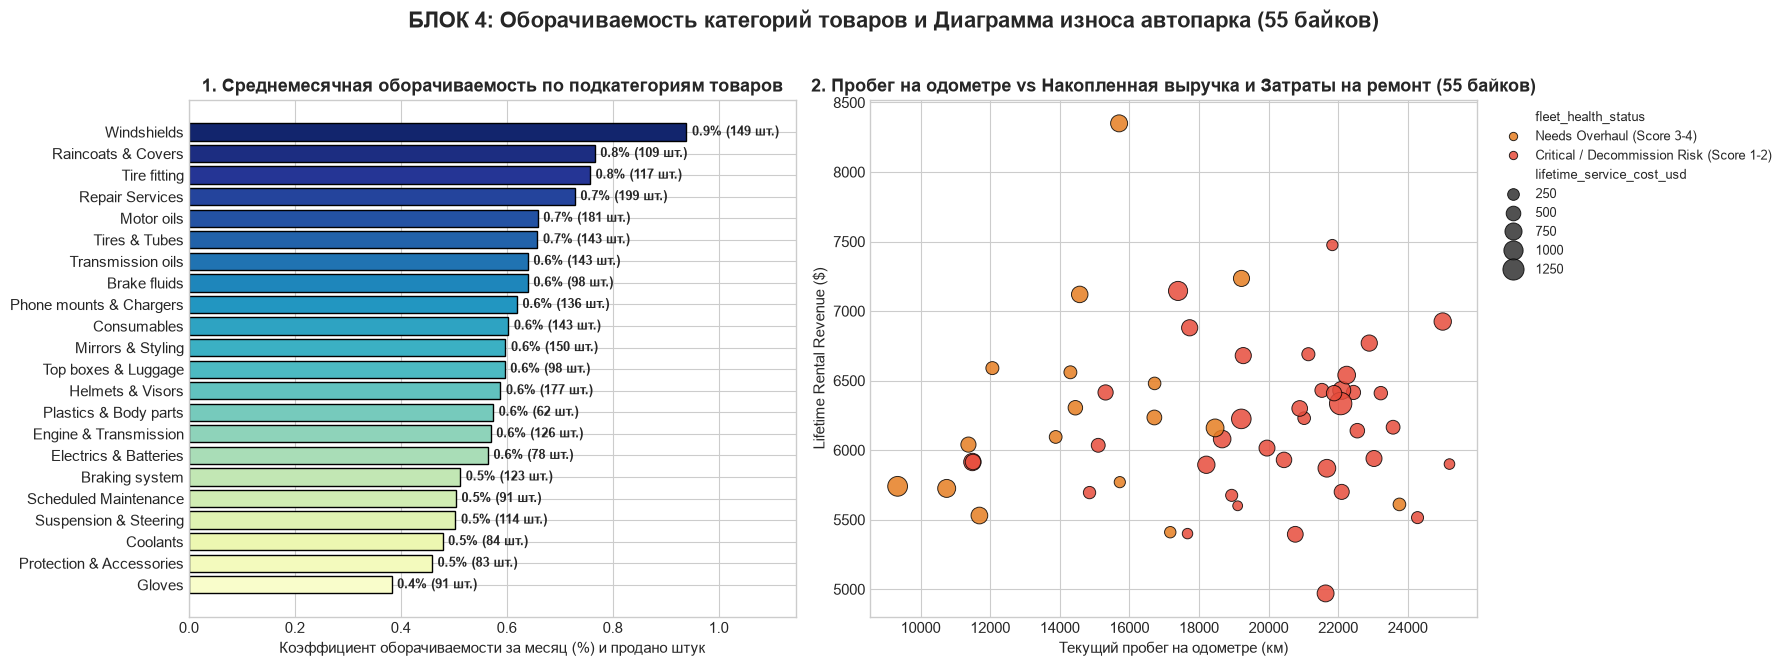

In [2]:
# %% [markdown]
# # ⚙️ Top Bikes Bangkok — Asset & Operations Management Dashboard
# Валидация операционных витрин: утилизация байков, оборачиваемость склада и «бутылочные горлышки» поставок/ремонтов

# %%
import warnings
import psycopg2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (16, 10)
plt.rcParams['font.size'] = 11

DB_CONFIG = {
    "dbname": "pet_dwh",
    "user": "pet_user",
    "password": "pet_password",
    "host": "localhost",
    "port": "5432"
}

def load_table(table_name):
    """Безопасная загрузка витрины из схемы aggregations"""
    with psycopg2.connect(**DB_CONFIG) as conn:
        with conn.cursor() as cur:
            cur.execute("""
                SELECT table_schema 
                FROM information_schema.tables 
                WHERE table_name = %s 
                LIMIT 1;
            """, (table_name,))
            row = cur.fetchone()
            if not row:
                raise ValueError(f"Таблица {table_name} не найдена в БД!")
            schema = row[0]
        return pd.read_sql(f"SELECT * FROM {schema}.{table_name}", conn)

# Загружаем 3 витрины-отчетности и 2 витрины-песочницы
df_ops_kpis = load_table("agg_monthly_ops_kpis")
df_fleet_util = load_table("agg_monthly_fleet_utilization")
df_supply_rep = load_table("agg_monthly_supply_and_repairs")
df_bikes_sb = load_table("stats_by_bikes")
df_inv_sb = load_table("stats_by_inventory")

for df in [df_ops_kpis, df_fleet_util, df_supply_rep, df_bikes_sb, df_inv_sb]:
    df['report_month'] = pd.to_datetime(df['report_month'])

# Отсекаем незавершенный текущий месяц на краю симуляции для чистоты трендов
max_complete_month = df_ops_kpis['report_month'].max() - pd.DateOffset(months=1)

df_ops_clean = df_ops_kpis[df_ops_kpis['report_month'] <= max_complete_month].sort_values('report_month')
df_fleet_clean = df_fleet_util[df_fleet_util['report_month'] <= max_complete_month].sort_values('report_month')
df_sup_clean = df_supply_rep[df_supply_rep['report_month'] <= max_complete_month].sort_values('report_month')
df_bikes_clean = df_bikes_sb[df_bikes_sb['report_month'] <= max_complete_month].sort_values('report_month')
df_inv_clean = df_inv_sb[df_inv_sb['report_month'] <= max_complete_month].sort_values('report_month')

print(f"✅ Операционные витрины загружены! Полный период: {df_ops_clean['report_month'].min().date()} — {df_ops_clean['report_month'].max().date()}")
print(f"Строк в agg_monthly_ops_kpis: {len(df_ops_clean)}")
print(f"Строк в agg_monthly_fleet_utilization: {len(df_fleet_clean)}")
print(f"Строк в agg_monthly_supply_and_repairs: {len(df_sup_clean)}")
print(f"Строк в stats_by_bikes: {len(df_bikes_clean)} | stats_by_inventory: {len(df_inv_clean)}")


# %% [markdown]
# ## Блок 1: Верхнеуровневые KPI Операционки (Утилизация, Поломки, Склад и Логистика)

# %%
fig, axes = plt.subplots(2, 2, figsize=(18, 11), sharex=True)
fig.suptitle('БЛОК 1: Операционные KPI (Утилизация автопарка, Полевой сервис, Оборачиваемость и Lead Time)', fontsize=16, fontweight='bold', y=0.98)

def highlight_ops_events(ax):
    # Наводнения (сентябрь 2024, октябрь 2025)
    ax.axvspan(pd.to_datetime('2024-09-01'), pd.to_datetime('2024-10-01'), color='#e74c3c', alpha=0.16, label='🌊 Наводнение (Шторм)')
    ax.axvspan(pd.to_datetime('2025-10-01'), pd.to_datetime('2025-11-01'), color='#e74c3c', alpha=0.16)
    # Логистический кризис (февраль-март 2025, июнь 2026)
    ax.axvspan(pd.to_datetime('2025-02-01'), pd.to_datetime('2025-03-20'), color='#f39c12', alpha=0.20, label='🚢 Логистический кризис')
    ax.axvspan(pd.to_datetime('2026-06-01'), pd.to_datetime('2026-07-05'), color='#f39c12', alpha=0.20)

# 1.1 North Star Операционки: Fleet Utilization Rate (%) & Активные байки
ax1 = axes[0, 0]
ax1.plot(df_ops_clean['report_month'], df_ops_clean['fleet_utilization_rate'] * 100, marker='o', linewidth=2.5, color='#2980b9', label='Fleet Utilization Rate (%)')
ax1.axhline(df_ops_clean['fleet_utilization_rate'].mean() * 100, color='gray', linestyle='--', alpha=0.7, label='Средняя утилизация')
highlight_ops_events(ax1)
ax1.set_title('1. North Star: Fleet Utilization Rate (% времени парка в аренде)', fontweight='bold')
ax1.set_ylabel('Утилизация парка (%)')
ax1.legend(loc='upper left')

# 1.2 Частота выездов механиков на 1000 км и Затраты на полевой сервис
ax2 = axes[0, 1]
ax2.plot(df_ops_clean['report_month'], df_ops_clean['field_services_per_1000km'], marker='s', linewidth=2.5, color='#c0392b', label='Выездов на 1000 км пробега')
ax2_twin = ax2.twinx()
ax2_twin.bar(df_ops_clean['report_month'], df_ops_clean['total_field_service_cost_usd'], width=18, alpha=0.22, color='#e67e22', label='Затраты на выезды ($)')
ax2_twin.grid(False)
highlight_ops_events(ax2)
ax2.set_title('2. Интенсивность поломок (Выездов на 1000 км) и Затраты на сервис ($)', fontweight='bold')
ax2.set_ylabel('Выездов на 1000 км', color='#c0392b')
ax2_twin.set_ylabel('Затраты на полевой ремонт ($)', color='#d35400')
ax2.legend(loc='upper left')

# 1.3 Lead Time поставок vs Lead Time ремонтов (в днях)
ax3 = axes[1, 0]
ax3.plot(df_ops_clean['report_month'], df_ops_clean['avg_procurement_lead_time_days'], marker='^', linewidth=2.5, color='#8e44ad', label='Lead Time закупок (дни)')
ax3.plot(df_ops_clean['report_month'], df_ops_clean['avg_repair_total_lead_time_days'], marker='d', linewidth=2.2, color='#16a085', label='Lead Time внешних ремонтов (дни)')
highlight_ops_events(ax3)
ax3.set_title('3. Длительность цепочек (Lead Time поставок и ремонтов, дни)', fontweight='bold')
ax3.set_ylabel('Среднее время цикла (дни)')
ax3.legend(loc='upper left')

# 1.4 Оборачиваемость склада (Inventory Turnover) и Out-of-Stock Rate (%)
ax4 = axes[1, 1]
ax4.plot(df_ops_clean['report_month'], df_ops_clean['avg_sku_turnover_ratio'] * 100, marker='o', linewidth=2.5, color='#27ae60', label='Avg SKU Turnover Ratio (%)')
ax4_twin = ax4.twinx()
ax4_twin.plot(df_ops_clean['report_month'], df_ops_clean['warehouse_out_of_stock_rate'] * 100, marker='x', linewidth=2.0, linestyle='--', color='#e74c3c', label='Out-of-Stock Rate (%)')
ax4_twin.grid(False)
highlight_ops_events(ax4)
ax4.set_title('4. Оборачиваемость запасов (Turnover) vs Доля дефицита (Out-of-Stock %)', fontweight='bold')
ax4.set_ylabel('Коэффициент оборачиваемости (%)', color='#27ae60')
ax4_twin.set_ylabel('Доля недель в Out-of-Stock (%)', color='#e74c3c')
ax4.legend(loc='upper left')
ax4_twin.legend(loc='upper right')

for ax in axes.flat:
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()


# %% [markdown]
# ## Блок 2: Эффективность автопарка, Окупаемость (ROI) и Износ во времени

# %%
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
fig.suptitle('БЛОК 2: Утилизация по моделям, Окупаемость (ROI) и Техническая деградация парка', fontsize=16, fontweight='bold', y=1.03)

# 2.1 Топ моделей байков по средней утилизации (Horizontal Bar)
ax1 = axes[0]
model_util = (
    df_fleet_clean.groupby('bike_title')
    .apply(lambda g: (g['sum_rented_days'].sum() / g['sum_available_days'].sum()) * 100)
    .sort_values(ascending=True)
    .tail(12)
)
bars1 = ax1.barh(model_util.index, model_util.values, color=sns.color_palette('Blues_r', len(model_util)), edgecolor='black')
ax1.bar_label(bars1, fmt='%.1f%%', padding=4, fontsize=9, fontweight='bold')
ax1.set_title('1. Топ-12 моделей по утилизации (% дней в аренде)', fontweight='bold')
ax1.set_xlabel('Средняя утилизация (%)')
ax1.margins(x=0.15)

# 2.2 Окупаемость (Lifetime ROI %) по брендам и типам байков на актуальном срезе
ax2 = axes[1]
latest_month = df_fleet_clean['report_month'].max()
latest_fleet = df_fleet_clean[df_fleet_clean['report_month'] == latest_month]
roi_by_type = (
    latest_fleet.groupby('bike_type')['avg_model_roi_ratio']
    .mean()
    .sort_values(ascending=False) * 100
)
sns.barplot(x=roi_by_type.index, y=roi_by_type.values, ax=ax2, palette='viridis', edgecolor='black')
ax2.bar_label(ax2.containers[0], fmt='%.0f%%', padding=4, fontweight='bold')
ax2.axhline(100, color='#e74c3c', linestyle='--', linewidth=1.5, label='Порог окупаемости (100%)')
ax2.set_title(f'2. Средний Lifetime ROI по классам байков (на {latest_month.strftime("%Y-%m")})', fontweight='bold')
ax2.set_xlabel('Класс байка (bike_type)')
ax2.set_ylabel('Окупаемость вложений (ROI, %)')
ax2.tick_params(axis='x', rotation=15)
ax2.legend()

# 2.3 Динамика технического здоровья парка по месяцам (100% Stacked Area / Bar по fleet_health_status)
ax3 = axes[2]
health_order = [
    'Optimal (Score 8-10)', 
    'Standard Wear (Score 5-7)', 
    'Needs Overhaul (Score 3-4)', 
    'Critical / Decommission Risk (Score 1-2)'
]
health_pivot = (
    df_bikes_clean.groupby(['report_month', 'fleet_health_status'])['bike_natural_key']
    .count()
    .unstack(fill_value=0)
)
existing_health = [h for h in health_order if h in health_pivot.columns]
health_pct = health_pivot[existing_health].div(health_pivot[existing_health].sum(axis=1), axis=0) * 100

health_colors = {'Optimal (Score 8-10)': '#2ecc71', 'Standard Wear (Score 5-7)': '#f1c40f', 'Needs Overhaul (Score 3-4)': '#e67e22', 'Critical / Decommission Risk (Score 1-2)': '#e74c3c'}
ax3.stackplot(
    health_pct.index,
    [health_pct[col] for col in existing_health],
    labels=existing_health,
    colors=[health_colors[col] for col in existing_health],
    alpha=0.85
)
ax3.set_title('3. Эволюция технического состояния парка (SCD4 Condition)', fontweight='bold')
ax3.set_ylabel('Доля автопарка (%)')
ax3.set_ylim(0, 100)
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax3.tick_params(axis='x', rotation=30)
ax3.legend(loc='lower left', fontsize=9)

plt.tight_layout()
plt.show()


# %% [markdown]
# ## Блок 3: Анализ «Бутылочных горлышек» (Lead Time ремонтов и поставок)

# %%
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
fig.suptitle('БЛОК 3: Анатомия «Бутылочных горлышек» в ремонтах (fct_repair) и поставках (fct_procurement)', fontsize=16, fontweight='bold', y=1.02)

# 3.1 Декомпозиция времени ремонта по месяцам (Inbound Transport + Active Workshop + Outbound Transport)
ax1 = axes[0]
rep_valid = df_sup_clean[df_sup_clean['completed_repairs_cnt'] > 0].copy()
rep_monthly_stages = rep_valid.groupby('report_month').apply(
    lambda g: pd.Series({
        '1. Доставка в гараж (Inbound)': np.average(g['avg_inbound_transport_days'], weights=g['completed_repairs_cnt']),
        '2. Работа в мастерской (Active Repair)': np.average(g['avg_active_repair_days'], weights=g['completed_repairs_cnt']),
        '3. Возврат в магазин (Outbound)': np.average(g['avg_outbound_transport_days'], weights=g['completed_repairs_cnt'])
    })
)
rep_monthly_stages.index = rep_monthly_stages.index.strftime('%Y-%m')
rep_monthly_stages.plot(
    kind='bar', 
    stacked=True, 
    ax=ax1, 
    color=['#3498db', '#e67e22', '#2ecc71'], 
    edgecolor='black', 
    width=0.75
)
ax1.set_title('1. Из чего состоит Lead Time ремонта по месяцам (Stacked Bar, дни)', fontweight='bold')
ax1.set_xlabel('Отчетный месяц')
ax1.set_ylabel('Средняя длительность этапа (дни)')
ax1.tick_params(axis='x', rotation=45)
# Оставляем каждую вторую подпись месяца, чтобы ось X не слипалась
for idx, label in enumerate(ax1.xaxis.get_ticklabels()):
    if idx % 2 != 0:
        label.set_visible(False)
ax1.legend(loc='upper left')

# 3.2 Декомпозиция времени закупки по локациям (Vendor Processing vs Carrier Transit)
ax2 = axes[1]
proc_valid = df_sup_clean[df_sup_clean['total_procured_qty'] > 0].copy()
loc_proc_stages = proc_valid.groupby('location_title').apply(
    lambda g: pd.Series({
        'Сборка у вендора (Vendor Processing)': np.average(g['avg_vendor_processing_days'], weights=g['total_procured_qty']),
        'Доставка перевозчиком (Carrier Transit)': np.average(g['avg_carrier_transit_days'], weights=g['total_procured_qty'])
    })
).sort_values(by='Доставка перевозчиком (Carrier Transit)', ascending=True)

loc_proc_stages.plot(
    kind='barh', 
    stacked=True, 
    ax=ax2, 
    color=['#9b59b6', '#1abc9c'], 
    edgecolor='black', 
    width=0.65
)
ax2.set_title('2. Lead Time поставок в разрезе локаций (Вендор vs Перевозчик, дни)', fontweight='bold')
ax2.set_xlabel('Среднее время доставки (дни)')
ax2.set_ylabel('Локация магазина / склада')
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()


# %% [markdown]
# ## Блок 4: Складская аналитика по категориям и Карта износа байков

# %%
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
fig.suptitle('БЛОК 4: Оборачиваемость категорий товаров и Диаграмма износа автопарка (55 байков)', fontsize=16, fontweight='bold', y=1.02)

# 4.1 Оборачиваемость и объем продаж по категориям 2-го уровня (level2_category)
ax1 = axes[0]
cat_stats = (
    df_inv_clean.groupby('level2_category')
    .agg(
        avg_turnover=('inventory_turnover_ratio', 'mean'),
        total_sold=('mtd_sold_qty', 'sum')
    )
    .sort_values('avg_turnover', ascending=True)
)
bars_cat = ax1.barh(cat_stats.index, cat_stats['avg_turnover'] * 100, color=sns.color_palette('YlGnBu', len(cat_stats)), edgecolor='black')
ax1.bar_label(bars_cat, labels=[f"{v*100:.1f}% ({s} шт.)" for v, s in zip(cat_stats['avg_turnover'], cat_stats['total_sold'])], padding=4, fontsize=9, fontweight='bold')
ax1.set_title('1. Среднемесячная оборачиваемость по подкатегориям товаров', fontweight='bold')
ax1.set_xlabel('Коэффициент оборачиваемости за месяц (%) и продано штук')
ax1.margins(x=0.22)

# 4.2 Карта износа и доходности 55 байков на актуальном срезе (Odometer vs Revenue vs Health Status)
ax2 = axes[1]
latest_bikes = df_bikes_clean.sort_values('report_month').groupby('bike_natural_key').last().reset_index()

sns.scatterplot(
    data=latest_bikes,
    x='current_odometer_km',
    y='lifetime_rental_revenue',
    hue='fleet_health_status',
    hue_order=[h for h in health_order if h in latest_bikes['fleet_health_status'].unique()],
    palette=health_colors,
    size='lifetime_service_cost_usd',
    sizes=(50, 260),
    alpha=0.85,
    edgecolor='black',
    ax=ax2
)
ax2.set_title('2. Пробег на одометре vs Накопленная выручка и Затраты на ремонт (55 байков)', fontweight='bold')
ax2.set_xlabel('Текущий пробег на одометре (км)')
ax2.set_ylabel('Lifetime Rental Revenue ($)')
ax2.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()